# Imports

In [1]:
import os
from typing import List, Tuple, Dict, Callable, Optional, Type
import copy

from tqdm.auto import tqdm
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# Colab settings

In [2]:
# import plotly.io as pio
# pio.renderers.default = "vscode"

# from google.colab import output
# output.enable_custom_widget_manager()

In [3]:
print("CUDA доступна:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Видеокарта:", torch.cuda.get_device_name(0))

CUDA доступна: False


In [4]:
# import kagglehub
# path = kagglehub.dataset_download("mayurmahurkar/stanford-car-body-type-data")
# print("Path to dataset files:", path)

In [5]:
# !mkdir data && mv /root/.cache/kagglehub/datasets/mayurmahurkar/stanford-car-body-type-data/versions/1/stanford_cars_type /content/data

# Constants

In [6]:
BASE_DIR_NAME = "data"
IMAGE_DIR_NAME = "stanford_cars_type"

RANDOM_SEED = 42

IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
VAL_TEST_SIZE = 0.3
TEST_RATIO = 0.5

NUM_WORKERS = 2

CNN_CONFIG = {
    "channels": [3, 32, 64, 128, 256, 512],
    "kernel_sizes": [5, 3, 3, 3, 3],
    "pool_kernel_size": 2,
    "pool_stride": 2,
    "conv_dropout": 0.05,
    "full_conn_dropout": 0.2,
    "full_conn_shapes": [128],
    "conv_f_activation": nn.ReLU,
    "full_conn_f_activation": nn.ReLU
}
CONV_NEXT_CONFIG = {
    "channels": [96, 192, 384, 768],
    "depths": [3, 3, 9, 3],
    "depth_wise_kernel_size": 7,
    "layer_norm_eps": 1e-6,
    "layer_scale_init_value": 1e-2,
    "drop_path_rate": 0.1
}

# Data loading

+ 8144 JPEG images
+ Cars photos
+ Classes:
    + 0: Cab
    + 1: Convertible
    + 2: Coupe
    + 3: Hatchback
    + 4: Minivan
    + 5: Other
    + 6: SUV
    + 7: Sedan
    + 8: Van
    + 9: Wagon

## Data paths

In [7]:
image_dir = os.path.join(BASE_DIR_NAME, IMAGE_DIR_NAME)
labels_dir_names = sorted(os.listdir(image_dir))

## Image checking

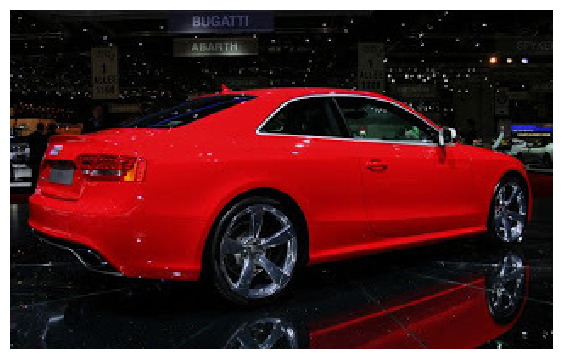

In [8]:
img = Image.open(os.path.join(image_dir, labels_dir_names[2], os.listdir(os.path.join(image_dir, labels_dir_names[2]))[0]))
plt.figure(figsize=(7, 7))
plt.imshow(img, interpolation='nearest')
plt.axis('off')
plt.show()

## Dataset creating

In [9]:
train_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
eval_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_dataset = datasets.ImageFolder(root=image_dir, transform=train_transform)
eval_dataset = datasets.ImageFolder(root=image_dir, transform=eval_transform)

## Data splitting

In [10]:
targets = train_dataset.targets
indices = list(range(len(targets)))

train_idx, val_test_idx, _, val_test_targets = train_test_split(
    indices,
    targets,
    test_size=VAL_TEST_SIZE,
    stratify=targets,
    random_state=RANDOM_SEED,
)
val_idx, test_idx = train_test_split(
    val_test_idx,
    test_size=TEST_RATIO,
    stratify=val_test_targets,
    random_state=RANDOM_SEED,
)

train_dataset = Subset(train_dataset, train_idx)
val_dataset = Subset(eval_dataset, val_idx)
test_dataset = Subset(eval_dataset, test_idx)

## DataLoader building

In [11]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    drop_last=True
)
valid_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

# Data analysis

In [12]:
label_counts = pd.DataFrame(
    {
        'Label': labels_dir_names,
        'Count': [len(os.listdir(os.path.join(image_dir, label))) for label in labels_dir_names],
    }
)
label_counts.loc[:, 'Percentage'] = label_counts['Count'] / label_counts['Count'].sum()

fig = px.bar(
    label_counts,
    x='Label',
    y='Count',
    text=label_counts['Count'],
    title='Распределение классов',
    labels={'Label': 'Класс', 'Count': 'Количество'},
    color='Count',
    color_continuous_scale='Blues',
    hover_data={'Percentage': ':.2f%'}
)

fig.update_traces(
    textposition='outside',
    hovertemplate="<b>Класс:</b> %{x}<br><b>Количество:</b> %{y}<br><b>Доля:</b> %{customdata[0]:.2%}<extra></extra>"
)

fig.update_layout(
    xaxis_title='Класс',
    yaxis_title='Количество',
    yaxis_range=[0, label_counts['Count'].max() * 1.15],
)

fig.show()

# Models

## Models building

### CNN

In [13]:
class CnnConvBlock(nn.Module):
    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        conv_kernel_size: int,
        padding: int,
        pool_kernel_size: int,
        pool_stride: int,
        dropout: float,
        f_activation: Type[nn.Module] | Callable[[], nn.Module],
    ) -> None:
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_size=conv_kernel_size,
                padding=padding,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            f_activation(),
            nn.MaxPool2d(
                kernel_size=pool_kernel_size,
                stride=pool_stride
            ),
            nn.Dropout2d(dropout)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)

In [14]:
class CnnFullConnectionBlock(nn.Module):
    def __init__(
        self,
        shape: Tuple[int, int],
        f_activation: Type[nn.Module] | Callable[[], nn.Module],
        dropout: float
    ) -> None:
        super().__init__()

        self.block = nn.Sequential(
            nn.Linear(
                shape[0],
                shape[1]
            ),
            f_activation(),
            nn.Dropout(dropout)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)

In [15]:
class Cnn(nn.Module):
    def __init__(
        self,
        num_classes: int,
        channels: List[int],
        kernel_sizes: List[int],
        pool_kernel_size: int,
        pool_stride: int,
        conv_dropout: float,
        full_conn_dropout: float,
        full_conn_shapes: List[int],
        conv_f_activation: Type[nn.Module] | Callable[[], nn.Module],
        full_conn_f_activation: Type[nn.Module] | Callable[[], nn.Module],
    ) -> None:
        super().__init__()

        if len(channels) != len(kernel_sizes) + 1:
            raise ValueError("Number of channels must be equal to number of kernel sizes + 1.")

        self.conv_module = nn.Sequential(
            *[
                CnnConvBlock(
                    in_channels=channels[i],
                    out_channels=channels[i + 1],
                    conv_kernel_size=kernel_sizes[i],
                    padding=kernel_sizes[i] // 2,
                    pool_kernel_size=pool_kernel_size,
                    pool_stride=pool_stride,
                    dropout=conv_dropout,
                    f_activation=conv_f_activation,
                ) 
                for i in range(len(kernel_sizes)) 
            ],
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.full_conn_module = nn.Sequential(
            nn.Flatten(),
            CnnFullConnectionBlock(
                shape=(
                    channels[-1],
                    full_conn_shapes[0]
                ),
                f_activation=full_conn_f_activation,
                dropout=full_conn_dropout
            ),
            *[
                CnnFullConnectionBlock(
                    shape=(
                        full_conn_shapes[i],
                        full_conn_shapes[i + 1]
                    ),
                    f_activation=full_conn_f_activation,
                    dropout=full_conn_dropout
                ) 
                for i in range(len(full_conn_shapes) - 1) 
            ],
            nn.Linear(
                full_conn_shapes[-1],
                num_classes,
            ),
        )

    def forward(self, x):
        x = self.conv_module(x)
        x = self.full_conn_module(x)
        
        return x

### ConvNeXt

In [16]:
class Permute(nn.Module):
    def __init__(
            self, 
            dims: List[int]
        ) -> None:
        super().__init__()

        self.dims = dims

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x.permute(*self.dims)

class LayerNorm(nn.Module):
    def __init__(
        self,
        channels: int,
        eps: float
    ) -> None:
        super().__init__()

        self.block = nn.Sequential(
            Permute([0, 2, 3, 1]),
            nn.LayerNorm(channels, eps=eps),
            Permute([0, 3, 1, 2])
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)

In [17]:
class DepthWiseConv2d(nn.Module):
    def __init__(
        self,
        in_channels: int,
        kernel_size: int,
    ) -> None:
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels=in_channels,
                out_channels=in_channels,
                kernel_size=kernel_size,
                padding=kernel_size // 2,
                groups=in_channels
            )
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)

In [18]:
class LayerScale(nn.Module):
    def __init__(
        self,
        channels: int,
        init_value: float = 1e-6,
        inplace: bool = False
    ) -> None:
        super().__init__()

        self.inplace = inplace
        self.gamma = nn.Parameter(torch.empty(1, channels, 1, 1))
        nn.init.constant_(self.gamma, init_value)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x.mul_(self.gamma) if self.inplace else x * self.gamma

In [19]:
class DropPath(nn.Module):
    def __init__(
        self,
        keep_prob: float,
        inplace: bool = False
    ) -> None:
        super().__init__()

        self.keep_prob = keep_prob
        self.inplace = inplace

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self.keep_prob >= 1.0 or not self.training:
            return x

        mask_shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        mask = x.new_empty(mask_shape).bernoulli_(self.keep_prob)
        mask.div_(self.keep_prob)

        return x.mul_(mask) if self.inplace else x * mask

In [20]:
class ConvNeXtBlock(nn.Module):
    def __init__(
        self,
        in_channels: int,
        depth: int,
        depth_wise_kernel_size: int,
        layer_norm_eps: float,
        layer_scale_init_value: float,
        drop_path_rate: float
    ) -> None:
        super().__init__()

        self.blocks = nn.ModuleList([
            nn.Sequential(
                DepthWiseConv2d(
                    in_channels=in_channels,
                    kernel_size=depth_wise_kernel_size
                ),
                LayerNorm(
                    channels=in_channels,
                    eps=layer_norm_eps
                ),
                nn.Conv2d(
                    in_channels=in_channels,
                    out_channels=in_channels * 4,
                    kernel_size=1,
                ),
                nn.GELU(),
                nn.Conv2d(
                    in_channels=in_channels * 4,
                    out_channels=in_channels,
                    kernel_size=1,
                ),
                LayerScale(
                    channels=in_channels,
                    init_value=layer_scale_init_value
                ),
                DropPath(1.0 - drop_path_rate)
            )
            for _ in range(depth)
        ])

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        for block in self.blocks:
            x = x + block(x)

        return x

In [21]:
class Downsample(nn.Module):
    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        layer_norm_eps: float,
    ) -> None:
        super().__init__()

        self.block = nn.Sequential(
            LayerNorm(
                channels=in_channels,
                eps=layer_norm_eps
            ),
            nn.Conv2d(
                in_channels=in_channels,
                out_channels=out_channels,
                kernel_size=2,
                stride=2
            )
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)


In [22]:
class ConvNeXt(nn.Module):
    def __init__(
        self,
        num_classes: int,
        in_channels: int,
        channels: List[int] = CONV_NEXT_CONFIG['channels'],
        depths: List[int] = CONV_NEXT_CONFIG['depths'],
        depth_wise_kernel_size: int = CONV_NEXT_CONFIG['depth_wise_kernel_size'],
        layer_norm_eps: float = CONV_NEXT_CONFIG['layer_norm_eps'],
        layer_scale_init_value: float = CONV_NEXT_CONFIG['layer_scale_init_value'],
        drop_path_rate: float = CONV_NEXT_CONFIG['drop_path_rate'],
    ) -> None:
        super().__init__()

        self.stem_cell = nn.Sequential(
            nn.Conv2d(
                in_channels=in_channels,
                out_channels=channels[0],
                kernel_size=4,
                stride=4
            ),
            LayerNorm(
                channels=channels[0],
                eps=layer_norm_eps
            )
        )

        self.stage_1 = nn.Sequential(
            ConvNeXtBlock(
                in_channels=channels[0],
                depth=depths[0],
                depth_wise_kernel_size=depth_wise_kernel_size,
                layer_norm_eps=layer_norm_eps,
                layer_scale_init_value=layer_scale_init_value,
                drop_path_rate=drop_path_rate,
            )
        )

        self.stage_2 = nn.Sequential(
            Downsample(
                in_channels=channels[0],
                out_channels=channels[1],
                layer_norm_eps=layer_norm_eps
            ),
            ConvNeXtBlock(
                in_channels=channels[1],
                depth=depths[1],
                depth_wise_kernel_size=depth_wise_kernel_size,
                layer_norm_eps=layer_norm_eps,
                layer_scale_init_value=layer_scale_init_value,
                drop_path_rate=drop_path_rate,
            )
        )

        self.stage_3 = nn.Sequential(
            Downsample(
                in_channels=channels[1],
                out_channels=channels[2],
                layer_norm_eps=layer_norm_eps
            ),
            ConvNeXtBlock(
                in_channels=channels[2],
                depth=depths[2],
                depth_wise_kernel_size=depth_wise_kernel_size,
                layer_norm_eps=layer_norm_eps,
                layer_scale_init_value=layer_scale_init_value,
                drop_path_rate=drop_path_rate,
            )
        )

        self.stage_4 = nn.Sequential(
            Downsample(
                in_channels=channels[2],
                out_channels=channels[3],
                layer_norm_eps=layer_norm_eps
            ),
            ConvNeXtBlock(
                in_channels=channels[3],
                depth=depths[3],
                depth_wise_kernel_size=depth_wise_kernel_size,
                layer_norm_eps=layer_norm_eps,
                layer_scale_init_value=layer_scale_init_value,
                drop_path_rate=drop_path_rate,
            )
        )

        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.LayerNorm(
                channels[-1], 
                eps=layer_norm_eps
            ),
            nn.Linear(
                channels[-1], 
                num_classes
            )
        )

        self.apply(self._init_weights)

    def _init_weights(self, m: nn.Module) -> None:
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.constant_(m.bias, 0)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.stem_cell(x)
        x = self.stage_1(x)
        x = self.stage_2(x)
        x = self.stage_3(x)
        x = self.stage_4(x)
        x = self.head(x)

        return x

## Model fitting

In [23]:
def run_epoch(
        model: nn.Module, 
        device: torch.device, 
        loader: DataLoader, 
        loss_function: nn.Module, 
        optimizer: Optional[torch.optim.Optimizer] = None, 
        max_grad_norm: Optional[float] = 1.0,
        desc: str = 'Epoch'
    ) -> Tuple[float, float]:
    """Runs a single training or evaluation epoch over a DataLoader.

    Args:
        model: PyTorch neural network model to train or evaluate.
        device: Target computation device (CPU or CUDA).
        loader: DataLoader providing batches of input images and corresponding labels.
        loss_function: Loss function module.
        optimizer: Optimization algorithm instance.
        max_grad_norm: Max norm for gradient clipping during training.
        desc: Progress bar description string.

    Returns:
        Tuple[float, float]: Average scalar loss and classification accuracy (0.0 to 1.0).
    """

    is_train = optimizer is not None
    model.train() if is_train else model.eval()
    
    progress_bar = tqdm(loader, desc=desc, leave=False, unit='batch')

    total_loss, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(is_train):
        for images, labels in progress_bar:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = loss_function(outputs, labels)
            
            if is_train:
                optimizer.zero_grad()
                loss.backward()
                if max_grad_norm is not None:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
                optimizer.step()

            batch_size = images.size(0)
            total_loss += loss.item() * batch_size
            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += batch_size

            progress_bar.set_postfix(
                loss=f"{total_loss / total:.4f}",
                acc=f"{correct / total:.4f}"
            )
            
    return total_loss / total, correct / total

def train_model(
        model: nn.Module, 
        train_loader: DataLoader, 
        valid_loader: DataLoader, 
        epochs: int = 25, 
        lr: float = 1e-3,
        weight_decay: float = 1e-2,
        label_smoothing: float = 0.1,
        patience: int = 7,
    ) -> Dict[str, List[float]]:
    """Trains a model across multiple epochs and evaluates it on validation data.

    Args:
        model: Neural network module to optimize.
        train_loader: DataLoader containing the training dataset batches.
        val_loader: DataLoader containing the validation dataset batches.
        epochs: Number of full training iterations over the dataset.
        lr: Learning rate parameter for the AdamW optimizer.
        weight_decay: L2 regularization coefficient to prevent overfitting.
        label_smoothing: Smoothing factor for CrossEntropyLoss.
        patience: Number of epochs without validation loss improvement before early stopping.

    Returns:
        Dict[str, List[float]]: Training history dictionary mapping metric names ('train_loss', 'valid_loss', 'train_accuracy', 'valid_accuracy') to per-epoch lists.
    """
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)

    loss = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)

    history = {
        'train_loss': [], 
        'valid_loss': [], 
        'train_accuracy': [], 
        'valid_accuracy': []
    }

    best_valid_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0

    epoch_bar = tqdm(range(1, epochs + 1), desc="Training Progress")
    
    for epoch in epoch_bar:
        train_loss, train_accuracy = run_epoch(
            model, device, train_loader, loss, optimizer=optimizer, desc=f"Train [{epoch}/{epochs}]"
        )
        valid_loss, valid_accuracy = run_epoch(
            model, device, valid_loader, loss, desc=f"Valid [{epoch}/{epochs}]"
        )

        scheduler.step()
        
        history['train_loss'].append(train_loss)
        history['valid_loss'].append(valid_loss)
        history['train_accuracy'].append(train_accuracy)
        history['valid_accuracy'].append(valid_accuracy)

        if valid_loss < best_valid_loss:
            best_valid_loss = valid_loss
            best_weights = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        epoch_bar.set_postfix(
            tr_loss=f"{train_loss:.3f}",
            val_loss=f"{valid_loss:.3f}",
            tr_acc=f"{train_accuracy:.3f}",
            val_acc=f"{valid_accuracy:.3f}",
            lr=f"{scheduler.get_last_lr()[0]:.1e}",
        )

        if epochs_without_improvement >= patience:
            epoch_bar.write(f"Early stopping on epoch {epoch}. Best valid_loss: {best_valid_loss:.4f}")
            break

    model.load_state_dict(best_weights)
    return history

In [24]:
modelCnn = Cnn(
    num_classes=len(labels_dir_names),
    channels=CNN_CONFIG["channels"],
    kernel_sizes=CNN_CONFIG["kernel_sizes"],
    pool_kernel_size=CNN_CONFIG["pool_kernel_size"],
    pool_stride=CNN_CONFIG["pool_stride"],
    conv_dropout=CNN_CONFIG["conv_dropout"],
    full_conn_dropout=CNN_CONFIG["full_conn_dropout"],
    full_conn_shapes=CNN_CONFIG["full_conn_shapes"],
    conv_f_activation=CNN_CONFIG["conv_f_activation"],
    full_conn_f_activation=CNN_CONFIG["full_conn_f_activation"],
)

historyCnn = train_model(modelCnn, train_loader, valid_loader, epochs=25, lr=1e-3)

Training Progress:   0%|          | 0/25 [00:00<?, ?it/s]

Train [1/25]:   0%|          | 0/178 [00:04<?, ?batch/s]

Valid [1/25]:   0%|          | 0/39 [00:03<?, ?batch/s]

Train [2/25]:   0%|          | 0/178 [00:03<?, ?batch/s]

Valid [2/25]:   0%|          | 0/39 [00:03<?, ?batch/s]

Train [3/25]:   0%|          | 0/178 [00:04<?, ?batch/s]

... (6 outputs left out)

Valid [6/25]:   0%|          | 0/39 [00:04<?, ?batch/s]

Train [7/25]:   0%|          | 0/178 [00:04<?, ?batch/s]

Exception ignored while calling deallocator <function _MultiProcessingDataLoaderIter.__del__ at 0x7f8a693b03b0>:
Traceback (most recent call last):
  File "/home/tonitrum/Projects/Work/ML/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/home/tonitrum/Projects/Work/ML/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py", line 1656, in _shutdown_workers
    w.join(timeout=_utils.MP_STATUS_CHECK_INTERVAL)
  File "/usr/lib/python3.14/multiprocessing/process.py", line 156, in join
    res = self._popen.wait(timeout)
  File "/usr/lib/python3.14/multiprocessing/popen_fork.py", line 41, in wait
    if not wait([self.sentinel], timeout):
  File "/usr/lib/python3.14/multiprocessing/connection.py", line 1190, in wait
    ready = selector.select(timeout)
  File "/usr/lib/python3.14/selectors.py", line 398, in select
    fd_event_list = self._selector.poll(timeout)
KeyboardInterrupt: 


RuntimeError: DataLoader worker (pid(s) 35828, 35858) exited unexpectedly

In [ ]:
modelConvNeXt = ConvNeXt(
    num_classes=len(labels_dir_names),
    in_channels=3
)

historyConvNeXt = train_model(modelConvNeXt, train_loader, valid_loader, epochs=25, lr=1e-3)

Training Progress:   0%|          | 0/25 [00:00<?, ?it/s]

Train [1/25]:   0%|          | 0/178 [00:00<?, ?batch/s]

Valid [1/25]:   0%|          | 0/39 [00:00<?, ?batch/s]

Train [2/25]:   0%|          | 0/178 [00:00<?, ?batch/s]

Valid [2/25]:   0%|          | 0/39 [00:00<?, ?batch/s]

Train [3/25]:   0%|          | 0/178 [00:00<?, ?batch/s]

... (31 outputs left out)

Train [19/25]:   0%|          | 0/178 [00:00<?, ?batch/s]

Valid [19/25]:   0%|          | 0/39 [00:00<?, ?batch/s]

Train [20/25]:   0%|          | 0/178 [00:00<?, ?batch/s]

: 

## Validation

